# Task 5: Decision Trees and Random Forests

**Objective:** Train a Decision Tree Classifier, visualize it, study overfitting, compare with a Random Forest, inspect feature importances, and use cross-validation.

Dataset: Breast Cancer Wisconsin Diagnostic dataset bundled with scikit-learn.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

RANDOM_STATE = 42

## 1. Load and inspect the dataset

In [13]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("\\nClass distribution:")
print(y.map({0: dataset.target_names[0], 1: dataset.target_names[1]}).value_counts())
display(X.head())

Dataset shape: (569, 30)
\nClass distribution:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Split into training and testing sets

A stratified split preserves the class proportions in both sets. The test set is held back for final evaluation.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 455
Testing samples: 114


## 3. Train a baseline Decision Tree

A deep, unconstrained tree can fit the training data very closely. Compare training and test accuracy to look for a generalization gap.

In [15]:
tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

tree_train_accuracy = accuracy_score(y_train, tree.predict(X_train))
tree_test_predictions = tree.predict(X_test)
tree_test_accuracy = accuracy_score(y_test, tree_test_predictions)

print(f"Decision Tree training accuracy: {tree_train_accuracy:.3f}")
print(f"Decision Tree test accuracy:     {tree_test_accuracy:.3f}")
print("\\nClassification report:")
print(classification_report(y_test, tree_test_predictions, target_names=dataset.target_names))

Decision Tree training accuracy: 1.000
Decision Tree test accuracy:     0.912
\nClassification report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114



## 4. Visualize the Decision Tree

The plot is limited to the first three levels so that it remains readable. The full model is still used for predictions.

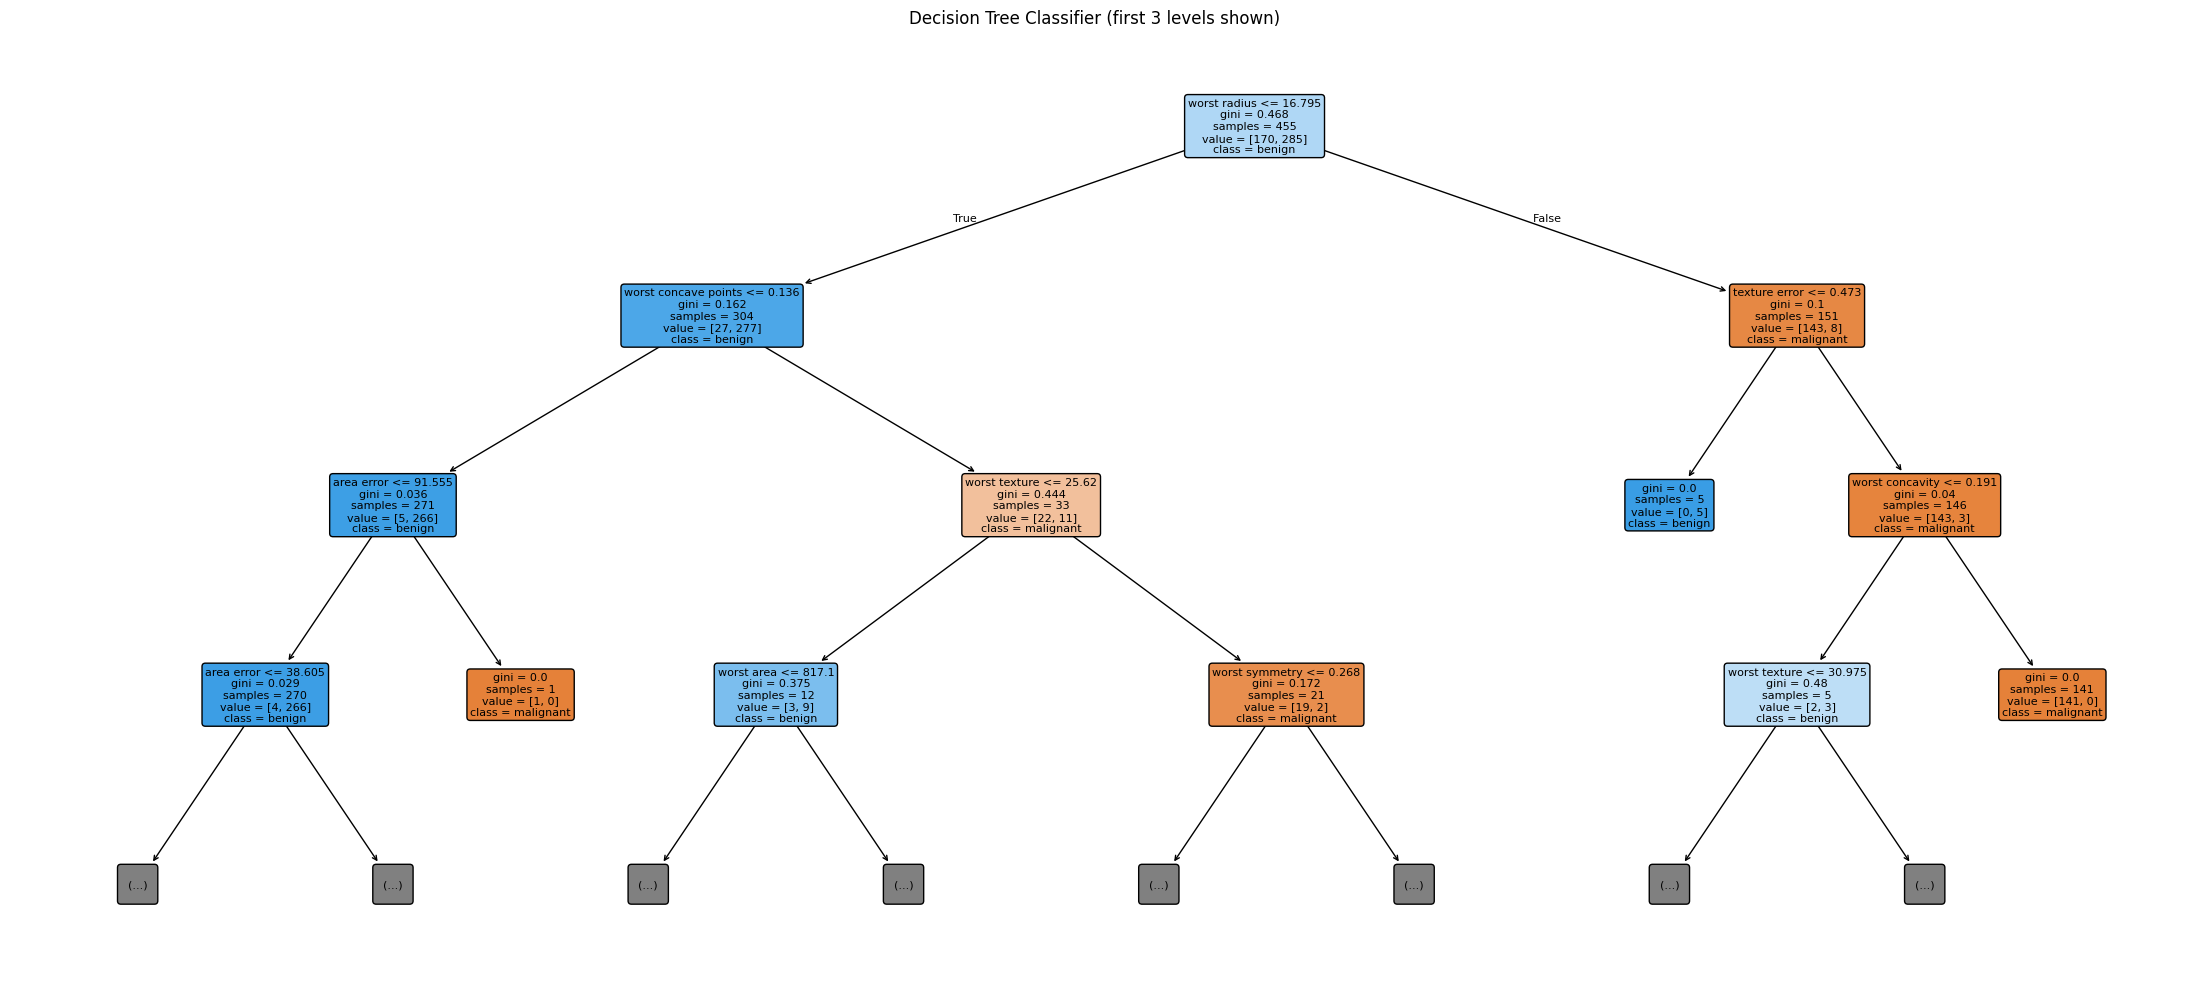

In [16]:
plt.figure(figsize=(22, 10))
plot_tree(
    tree,
    feature_names=list(X.columns),
    class_names=list(dataset.target_names),
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree Classifier (first 3 levels shown)")
plt.tight_layout()
plt.show()

## 5. Control overfitting with tree depth

Train several trees with different maximum depths and compare their training and test accuracy.

,max_depth,train_accuracy,test_accuracy
0,1,0.923077,0.921053
1,2,0.958242,0.894737
2,3,0.975824,0.938596
3,4,0.986813,0.938596
4,5,0.993407,0.921053
5,7,1.000000,0.912281
6,None,1.000000,0.912281


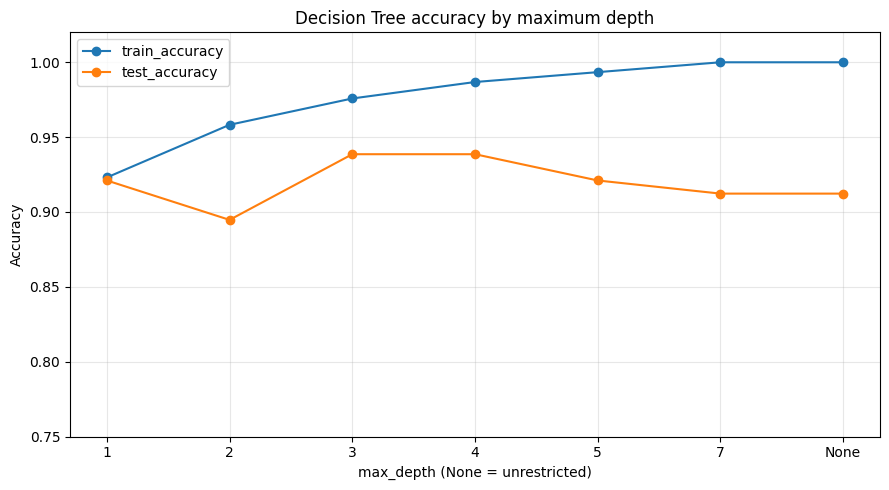

In [17]:
depth_results = []
for depth in [1, 2, 3, 4, 5, 7, None]:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    depth_results.append({
        "max_depth": str(depth),
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, model.predict(X_test))
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)

ax = depth_df.set_index("max_depth")[["train_accuracy", "test_accuracy"]].plot(
    marker="o", figsize=(9, 5)
)
ax.set_title("Decision Tree accuracy by maximum depth")
ax.set_xlabel("max_depth (None = unrestricted)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.75, 1.02)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Train a regularized Decision Tree and a Random Forest

The regularized tree limits depth and requires a minimum number of samples per leaf. The Random Forest combines predictions from many randomized trees.

In [18]:
regularized_tree = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=5, random_state=RANDOM_STATE
)
forest = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=-1
)

models = {
    "Regularized Decision Tree": regularized_tree,
    "Random Forest": forest
}

comparison = []
for name, model in models.items():
    model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    comparison.append({
        "model": name,
        "train_accuracy": train_acc,
        "test_accuracy": test_acc
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,model,train_accuracy,test_accuracy
0,Regularized Decision Tree,0.975824,0.921053
1,Random Forest,1.000000,0.947368


## 7. Confusion matrix for the Random Forest

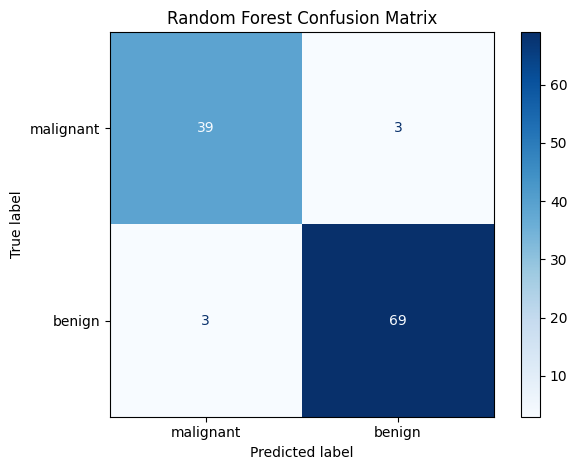

              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114



In [19]:
forest_predictions = forest.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions,
    display_labels=dataset.target_names,
    cmap="Blues"
)
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, forest_predictions, target_names=dataset.target_names))

## 8. Evaluate using stratified 5-fold cross-validation

Cross-validation estimates performance across multiple train/validation splits. These scores are calculated on the training portion only; the held-out test set remains separate.

In [20]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = []

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    cv_results.append({
        "model": name,
        "fold_accuracies": np.round(scores, 4).tolist(),
        "mean_cv_accuracy": scores.mean(),
        "std_cv_accuracy": scores.std()
    })

cv_df = pd.DataFrame(cv_results)
display(cv_df)

,model,fold_accuracies,mean_cv_accuracy,std_cv_accuracy
0,Regularized Decision Tree,"[0.9231, 0.9451, 0.9121, 0.9231, 0.956]",0.931868,0.016150
1,Random Forest,"[0.956, 0.967, 0.9341, 0.978, 0.978]",0.962637,0.016447


## 9. Interpret Random Forest feature importances

Importance is based on mean decrease in impurity. It can help identify features useful to the model, but it is not proof that a feature causes the outcome. Correlated features can share or distort importance.

,importance
worst perimeter,0.145030
worst area,0.138883
worst concave points,0.109683
mean concave points,0.096527
worst radius,0.078675
mean radius,0.049801
mean concavity,0.049763
worst concavity,0.043556
mean perimeter,0.042547
area error,0.038818


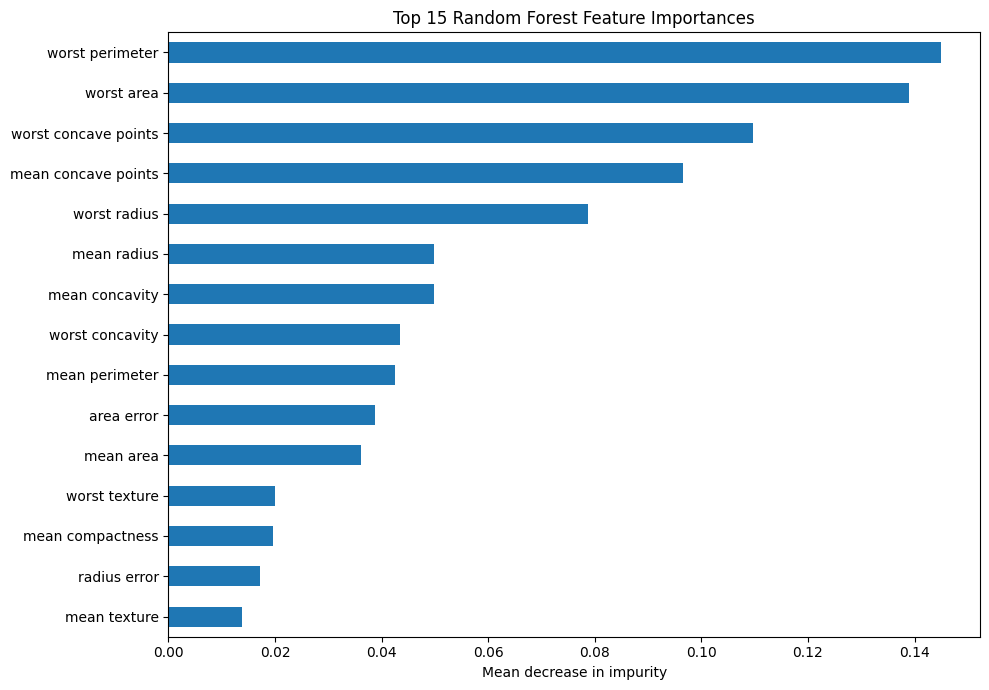

In [21]:
importances = pd.Series(forest.feature_importances_, index=X.columns)
top_importances = importances.sort_values(ascending=False).head(15)

display(top_importances.rename("importance").to_frame())

plt.figure(figsize=(10, 7))
top_importances.sort_values().plot(kind="barh")
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.show()

## 10. Final summary

Run the following cell to print the metrics you can include in your submission. Use the actual values produced by your environment.

In [22]:
print("FINAL RESULTS")
print("=" * 50)
print(f"Baseline Decision Tree — train: {tree_train_accuracy:.3f}, test: {tree_test_accuracy:.3f}")
for row in comparison:
    print(f"{row['model']} — train: {row['train_accuracy']:.3f}, test: {row['test_accuracy']:.3f}")
print("\\nCross-validation:")
for row in cv_results:
    print(f"{row['model']}: mean={row['mean_cv_accuracy']:.3f}, std={row['std_cv_accuracy']:.3f}")

FINAL RESULTS
Baseline Decision Tree — train: 1.000, test: 0.912
Regularized Decision Tree — train: 0.976, test: 0.921
Random Forest — train: 1.000, test: 0.947
\nCross-validation:
Regularized Decision Tree: mean=0.932, std=0.016
Random Forest: mean=0.963, std=0.016


## Conclusion

- Decision Trees are interpretable but can overfit when allowed to grow too deep.
- Limiting `max_depth` and increasing `min_samples_leaf` can improve generalization.
- Random Forests reduce variance by combining many trees and often provide stronger, more stable results.
- Cross-validation provides a more robust estimate than relying on one split.
- Feature importance is useful for exploration, but should be interpreted carefully.

**Before submitting:** run all cells, inspect the generated results, save the notebook with outputs, and upload the repository to GitHub.